# Classical NLP and ML Baselines

Goal: establish simple, interpretable baselines before introducing embeddings or LLMs.

> **How well can traditional NLP methods solve the problem before we add more complex AI approaches?**

Three baselines:
1. TF-IDF → Logistic Regression → feedback **category** prediction
2. TF-IDF → Logistic Regression → **sentiment** classification
3. TF-IDF → KMeans → unsupervised **topic discovery**

Every later method (embeddings, BERTopic, LLM) has to beat these numbers to justify its extra cost and complexity.

Input: `data/processed/cleaned_feedback.csv` from the EDA notebook. Outputs are written to `results/`.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score, silhouette_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline

RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

## 1. Load the cleaned data

EDA found that about 17% of rows belong to duplicate sets. Looking closer, every duplicated text has a **different category on each copy**: *"good"* appears once in every category, *"average"* 7 times. These look like short answers to a separate survey question per category (*"How is the library?"* → *"good"*), so the category comes from the question, not from the text.

Keep all copies. Dropping duplicates would keep one copy with an arbitrary category label and change the real distribution of comments.

In [2]:
df = pd.read_csv("../data/processed/cleaned_feedback.csv")
len(df)

724

## 2. 5-fold cross-validation, grouped by text

With a single 80/20 split the test set has only ~145 comments, and scores move by several points depending on which comments land in it. Cross-validation uses every comment for testing once:

1. Split the data into 5 folds.
2. Train on 4 folds, predict the 5th. Repeat so each fold is predicted once.
3. Every comment ends up with an **out-of-fold prediction** from a model that never saw it.

If the same comment is in both the training and the test folds, the model is tested on text it has already seen and the scores are inflated (data leakage). Grouping prevents this: every copy of a comment goes to the same fold. The group key is the text lowercased with punctuation removed, so *"Good"*, *"good"* and *"GOOD."* count as the same comment.

`StratifiedGroupKFold` also keeps the sentiment proportions similar in each fold. The folds are computed once and reused, so every model is evaluated on exactly the same splits.

The duplicated short comments show an honest limit of text-only classification: *"good"* carries no information about category, so the category model can only guess.

In [3]:
groups = df["text"].str.lower().str.replace(r"[^\w\s]", "", regex=True).str.strip()

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(df, df["sentiment"], groups))

df["fold"] = 0
for k, (train_idx, test_idx) in enumerate(folds):
    df.loc[test_idx, "fold"] = k

df["fold"].value_counts().sort_index()

fold
0    145
1    145
2    145
3    145
4    144
Name: count, dtype: int64

Check: no comment appears in both the training and the test part of any fold.

In [4]:
for train_idx, test_idx in folds:
    print(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))

set()
set()
set()
set()
set()


## 3. Baseline 1: TF-IDF → Logistic Regression → category

TF-IDF turns each comment into a vector of word weights: words frequent in this comment but rare across the corpus get high weight. Logistic regression then learns one weight per word per category.

The vectoriser uses single words only (the default `ngram_range=(1, 1)`). Adding word pairs with `ngram_range=(1, 2)` (e.g. *"not good"* as one feature) was tested with 5-fold grouped cross-validation and made no measurable difference (category macro-F1 0.631 vs 0.623, sentiment 0.737 vs 0.732). Pairs more than quadruple the features (1,100 → 4,843) and most appear only once, comments are short (median 7 words), and *not* alone is already a strong negative signal. Worth retesting on larger data with longer comments.

Stop words are **kept**: sklearn's English stop-word list contains *not, no, never, but, very, too*, which carry meaning in feedback.

The vectoriser sits inside the pipeline, so its vocabulary and IDF weights are learned from the training folds only.

In [5]:
category_model = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
df["category_pred"] = cross_val_predict(category_model, df["text"], df["category"], cv=folds)

print(classification_report(df["category"], df["category_pred"]))

                    precision    recall  f1-score   support

    course_content       0.71      0.62      0.66       124
       examination       0.59      0.57      0.58       122
   extracurricular       0.52      0.62      0.57       118
           labwork       0.65      0.62      0.63       117
library_facilities       0.79      0.60      0.68       118
          teaching       0.57      0.71      0.63       125

          accuracy                           0.62       724
         macro avg       0.64      0.62      0.63       724
      weighted avg       0.64      0.62      0.63       724



Macro-F1 averages F1 over classes with equal weight, so a small class counts as much as a large one. Accuracy can look good while a minority class is badly predicted. Macro-F1 exposes that.

This report pools the out-of-fold predictions of all 5 folds. Section 5 adds how much macro-F1 varies from fold to fold.

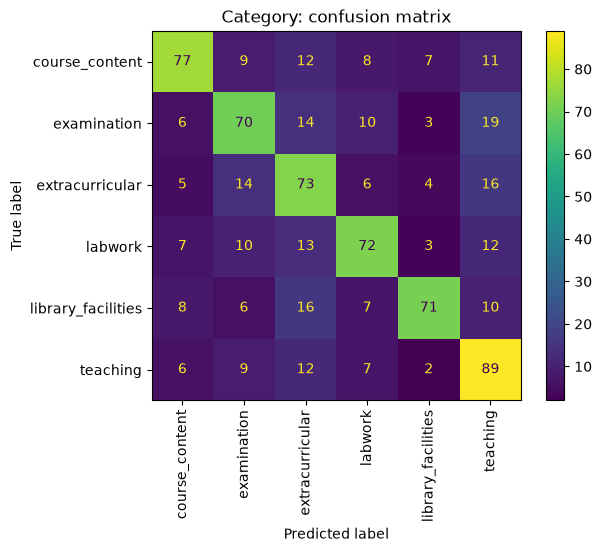

In [7]:
ConfusionMatrixDisplay.from_predictions(df["category"], df["category_pred"], xticks_rotation=90)
plt.title("Category: confusion matrix")
plt.savefig(RESULTS / "confusion_matrix.png", bbox_inches="tight")
plt.show()

Which words drive each category? Large positive weights are the words the model relies on. If they are generic (e.g. *good*, *very*), the model is learning sentiment-ish vocabulary rather than the topic.

`cross_val_predict` doesn't keep the fitted models, so fit once on all comments to inspect the weights. This model is only for interpretation; the scores above come from cross-validation.

In [8]:
category_model.fit(df["text"], df["category"])

vectorizer = category_model.named_steps["tfidfvectorizer"]
classifier = category_model.named_steps["logisticregression"]
words = vectorizer.get_feature_names_out()

pd.DataFrame({c: words[coef.argsort()[::-1][:10]] for c, coef in zip(classifier.classes_, classifier.coef_)})

,course_content,examination,extracurricular,labwork,library_facilities,teaching
0,courses,pattern,activities,lab,library,teaching
1,course,paper,extracurricular,labs,books,delivery
2,content,checking,best,work,facilities,interaction
3,depth,examination,participate,practical,available,lecture
4,material,exam,students,practicals,book,punctuality
5,knowledge,strict,held,evaluations,hardworking,teachers
6,knowledgeable,distribution,great,hours,are,punctual
7,proper,examinations,extraordinary,must,handling,lectures
8,subjects,all,many,pretty,rough,faculty
9,syllabus,marks,they,marks,fine,but


Misclassified comments: read these to see *why* the model fails (short text, multiple topics, label noise?).

In [9]:
df[df["category"] != df["category_pred"]][["text", "category", "category_pred"]]

,text,category,category_pred
1,Satisfactory,library_facilities,labwork
2,very good.,library_facilities,examination
4,Yes,labwork,extracurricular
6,excellent,teaching,extracurricular
10,Not so good,examination,course_content
...,...,...,...
712,Everything is pretty well organised,examination,teaching
718,I am really enjoying,extracurricular,teaching
719,satisfactory,teaching,labwork
720,good enough,teaching,course_content


### 3a. Comments with no topic in the text

Some texts (*"good"*, *"excellent"*, *"average"*) appear under several different categories. Their category comes from the survey question, not from the words, so no text-only model can predict it. Flag every comment whose text (normalised, as in the group key) appears under more than one category.

In [10]:
no_topic = df.groupby(groups)["category"].transform("nunique") > 1
print(f"No-topic comments: {no_topic.sum()} ({no_topic.mean():.0%})")

df.loc[no_topic, "text"].str.lower().value_counts().head(10)

No-topic comments: 154 (21%)


text
good            17
excellent       12
very good       12
average         11
yes              6
good.            6
not good         5
it is good       5
its good         5
satisfactory     4
Name: count, dtype: int64

Score the category model on all comments and on comments that have a topic in the text:
- **all comments**: what to expect in production, where these comments keep arriving
- **comments with a topic**: how well lexical features recognise a topic when there is one

On the no-topic comments themselves, accuracy should be near chance (1 in 6).

In [11]:
with_topic = df[~no_topic]

print("macro-F1, all comments:        ", round(f1_score(df["category"], df["category_pred"], average="macro"), 3))
print("macro-F1, comments with topic: ", round(f1_score(with_topic["category"], with_topic["category_pred"], average="macro"), 3))
print("accuracy, no-topic comments:   ", round((df["category"] == df["category_pred"])[no_topic].mean(), 3))

macro-F1, all comments:         0.626
macro-F1, comments with topic:  0.752
accuracy, no-topic comments:    0.156


Leaving these comments out of the category task makes the score look better, but the model is no better. Report both numbers, and note that the taxonomy needs a **"general / no specific theme"** bucket instead of forcing every comment into a category.

Limits of this check:
- It only catches texts that appear more than once. A one-off *"nice"* has the same problem but isn't flagged.
- It uses the labels to find these comments. In production there are no labels, so a rule (e.g. very short and no topic words) would be needed.

## 4. Baseline 2: TF-IDF → Logistic Regression → sentiment

Same pipeline, sentiment labels. EDA showed sentiment is imbalanced (~62% positive), so train it twice:
- default: every training comment counts equally
- `class_weight="balanced"`: errors on rare classes (neutral, negative) cost more

Compare recall on *neutral* and *negative* between the two.

In [12]:
sentiment_model = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
df["sentiment_pred"] = cross_val_predict(sentiment_model, df["text"], df["sentiment"], cv=folds)

print(classification_report(df["sentiment"], df["sentiment_pred"]))

              precision    recall  f1-score   support

    negative       0.71      0.50      0.59       139
     neutral       0.71      0.40      0.51       134
    positive       0.79      0.96      0.86       451

    accuracy                           0.77       724
   macro avg       0.74      0.62      0.66       724
weighted avg       0.76      0.77      0.75       724



In [13]:
balanced_model = make_pipeline(
    TfidfVectorizer(), LogisticRegression(max_iter=1000, class_weight="balanced")
)
df["sentiment_balanced_pred"] = cross_val_predict(balanced_model, df["text"], df["sentiment"], cv=folds)

print(classification_report(df["sentiment"], df["sentiment_balanced_pred"]))

              precision    recall  f1-score   support

    negative       0.63      0.71      0.67       139
     neutral       0.62      0.69      0.65       134
    positive       0.92      0.85      0.88       451

    accuracy                           0.79       724
   macro avg       0.72      0.75      0.73       724
weighted avg       0.81      0.79      0.80       724



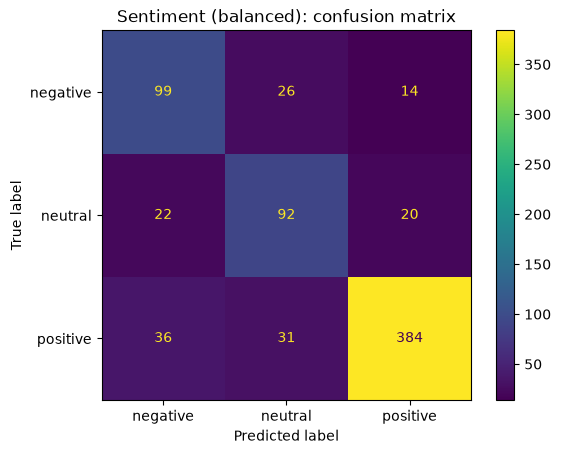

In [14]:
ConfusionMatrixDisplay.from_predictions(df["sentiment"], df["sentiment_balanced_pred"])
plt.title("Sentiment (balanced): confusion matrix")
plt.savefig(RESULTS / "confusion_matrix_sentiment.png", bbox_inches="tight")
plt.show()

## 5. Save classification metrics

For each model:
- macro-averaged precision, recall and F1, plus accuracy, from the pooled out-of-fold predictions
- `f1_fold_mean` and `f1_fold_std`: macro-F1 computed separately on each fold. The standard deviation shows how much a single ~145-comment test set can move the score. Differences between models smaller than this are noise.

In [15]:
rows = []
for name, data, target, pred in [
    ("category", df, "category", "category_pred"),
    ("category_with_topic", with_topic, "category", "category_pred"),
    ("sentiment", df, "sentiment", "sentiment_pred"),
    ("sentiment_balanced", df, "sentiment", "sentiment_balanced_pred"),
]:
    report = classification_report(data[target], data[pred], output_dict=True)
    fold_f1 = pd.Series([f1_score(d[target], d[pred], average="macro") for _, d in data.groupby("fold")])
    rows.append({
        "model": name,
        **report["macro avg"],
        "accuracy": report["accuracy"],
        "f1_fold_mean": fold_f1.mean(),
        "f1_fold_std": fold_f1.std(),
    })

metrics = pd.DataFrame(rows).drop(columns="support").round(3)
metrics.to_csv(RESULTS / "baseline_classification_metrics.csv", index=False)
metrics

,model,precision,recall,f1-score,accuracy,f1_fold_mean,f1_fold_std
0,category,0.639,0.624,0.626,0.624,0.628,0.017
1,category_with_topic,0.759,0.750,0.752,0.751,0.751,0.014
2,sentiment,0.737,0.621,0.656,0.768,0.651,0.085
3,sentiment_balanced,0.722,0.750,0.734,0.794,0.737,0.036


## 6. Baseline 3: TF-IDF → KMeans → topic discovery

Now ignore the labels and ask: do comments group into themes by themselves?

Differences from the classifiers:
- No cross-validation: clustering has no labels to predict, so fit on all comments.
- Stop words are **removed**: without labels to guide it, KMeans would otherwise group comments by shared function words (*the, was, very*) instead of topic.
- `min_df=2` drops words that appear in only one comment, since they can't link comments together.

TF-IDF vectors are length-normalised, so KMeans' Euclidean distance behaves like cosine distance here.

In [16]:
cluster_vectorizer = TfidfVectorizer(stop_words="english", min_df=2)
X = cluster_vectorizer.fit_transform(df["text"])
X.shape

(724, 354)

Comments made only of stop words and words that appear in a single comment have nothing left after filtering. Their vector is all zeros, so KMeans assigns them to a cluster arbitrarily.

In [17]:
(X.getnnz(axis=1) == 0).sum()

np.int64(17)

### 6a. Choosing k

Silhouette score (−1 to 1) measures how much closer each comment is to its own cluster than to the nearest other cluster. Near 0 means clusters overlap heavily. Short, sparse TF-IDF vectors usually give low scores, so compare values across k rather than reading them in absolute terms.

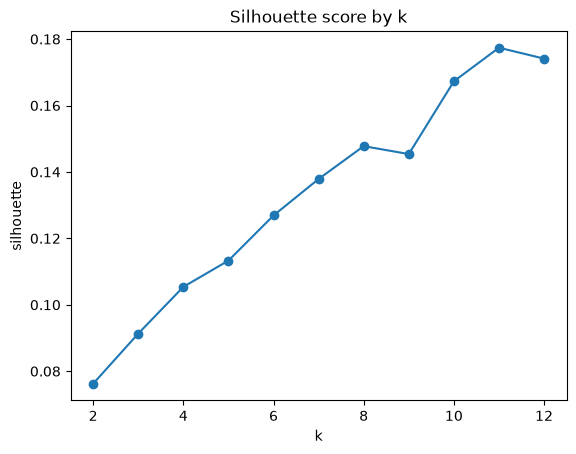

In [18]:
scores = {}
for k in range(2, 13):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    scores[k] = silhouette_score(X, labels, metric="cosine")

pd.Series(scores).plot(marker="o", title="Silhouette score by k", xlabel="k", ylabel="silhouette")
plt.show()

Use k = 6 below, the number of existing categories, so the clusters can be compared with the labels. Try the k with the best silhouette as well and see whether the clusters are easier or harder to name.

In [19]:
K = 6
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X)
print(f"silhouette (k={K}): {silhouette_score(X, df['cluster'], metric='cosine'):.3f}")

df["cluster"].value_counts().sort_index()

silhouette (k=6): 0.127


cluster
0     90
1     68
2    484
3     41
4     15
5     26
Name: count, dtype: int64

### 6b. Interpreting the clusters

Top terms come from each cluster centre: the words with the highest average TF-IDF weight in that cluster. Can you give each cluster a short theme name from its terms and examples?

Watch for two typical KMeans-on-TF-IDF failures:
- a very large **catch-all** cluster holding everything that didn't fit elsewhere
- a cluster formed by a **generic word** (e.g. *good*) that groups comments by tone rather than topic

In [20]:
terms = cluster_vectorizer.get_feature_names_out()
top_terms = [", ".join(terms[center.argsort()[::-1][:10]]) for center in kmeans.cluster_centers_]

cluster_summary = pd.DataFrame({
    "cluster": range(K),
    "size": df["cluster"].value_counts().sort_index(),
    "top_terms": top_terms,
    "example": df.groupby("cluster")["text"].first(),
})
cluster_summary.to_csv(RESULTS / "tfidf_cluster_summary.csv", index=False)
cluster_summary

,cluster,size,top_terms,example
cluster,,,,
0,0,90,"good, students, know, facility, faculties, fac...",all these are good
1,1,68,"university, activities, best, extracurricular,...",Our university has lot of extracurricular goin...
2,2,484,"good, books, lab, library, course, students, c...",Satisfactory
3,3,41,"pattern, checking, paper, exam, marks, good, e...","exam pattern is good, very well marks distribu..."
4,4,15,"average, way, courses, term, based, content, t...",Average
5,5,26,"excellent, facilities, library, going, lecture...",excellent


In [21]:
for c in range(K):
    print(f"--- cluster {c}: {top_terms[c]}")
    for text in df[df["cluster"] == c]["text"].sample(5, random_state=42):
        print("  ", text)

--- cluster 0: good, students, know, facility, faculties, faculty, fair, faults, feature, felt
   Very good
   Very good indeed.
   very good
   Good.
   all these are good
--- cluster 1: university, activities, best, extracurricular, good, students, terms, held, lot, regarding
   Capacity of library is less compared to size of university.
   It is best
   extracurricular activities are also good
   The university consists of a whole world in itself.It is diverse and manages to conduct all events properly.I love being the part of this university where we get equal and all opportunities in all respects and fields.
   No idea about the extracurricular activities.
--- cluster 2: good, books, lab, library, course, students, content, knowledge, work, bad
   some time lab is not proper working , some teacher's practical knowledge is less on the other side evaluations is not that much good
   it is good leaning in lab but the lab instruments are not properly working
   its very tough and very

### 6c. Do clusters match the existing categories?

Each row is a cluster, each column a category. A cluster that recovers a category has most of its comments in one column. Clusters spread evenly across columns found something other than the category, often sentiment or comment length.

In [22]:
pd.crosstab(df["cluster"], df["category"])

category,course_content,examination,extracurricular,labwork,library_facilities,teaching
cluster,,,,,,
0,12,18,14,15,14,17
1,4,5,39,1,3,16
2,103,52,57,94,92,86
3,0,40,0,1,0,0
4,3,2,2,3,3,2
5,2,5,6,3,6,4


## 7. Save findings

In [25]:
findings = f"""# Baseline Findings

## Classification (macro-averaged, 5-fold grouped cross-validation, {len(df)} comments)

{metrics.to_string(index=False)}

## TF-IDF + KMeans (k={K})

{cluster_summary[["cluster", "size", "top_terms"]].to_string(index=False)}

"""

(RESULTS / "baseline_findings.md").write_text(findings)

1311